In [1083]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.optimize import curve_fit
from matplotlib.patches import Ellipse

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 20})

ročno fitanje na nelin

In [1084]:
data = np.loadtxt('farmakoloski.dat')
x_doza = []
y_odziv = []
dy_odziv = []
for vrstica in data:
    x_doza.append(vrstica[0])
    y_odziv.append(vrstica[1])
    dy_odziv.append(vrstica[2]) #napaka?
x_doza = np.array(x_doza)
y_odziv = np.array(y_odziv)
dy_odziv = np.array(dy_odziv)

In [1085]:
def y(x, y0, a): #original nelin
    return y0*x / (x+a)
def f_lin(x, a1, a2):
    return a1  + a2 * 1/x
def ksi(y, sigma, a): #ksi kvadrat
    a1, a2 = a
    fit  = 0
    for i in range(len(y)):
        #napaka_nova = dy_odziv/y_odziv**2
        fit += ((y[i] - y(x_doza[i], a1, a2))**2 / sigma[i])**2
    return fit

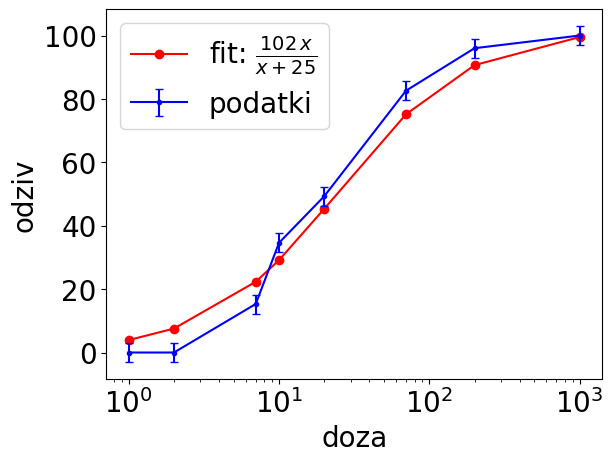

In [1086]:
#plt.plot(x_doza, y_odziv,'-o')
y0 = 102
a = 25
#print(ksi(list(y_odziv), list(dy_odziv), [1/y0, a/y0]))
y_en = [ y(i, y0, a) for i in x_doza] # y0, a ROČNO!
plt.plot(x_doza, y_en, 'r-o', label=f'fit: $\\frac{{{int(y0)}\,x}}{{x+{int(a)}}}$')
plt.errorbar(x_doza, y_odziv, dy_odziv, fmt='b.-', capsize=3, label='podatki') #podatki
plt.xlabel('doza')
plt.ylabel('odziv')
plt.xscale('log')
plt.legend()
#plt.savefig('slike/rocni_fit_farm.pdf', bbox_inches='tight')

fitanje na linearizirano funkcijo

In [1087]:
def Akj(N, phi, sigma, k ,j):
    A = 0
    for i in range(N):
        A += phi[k][i] * phi[j][i] / sigma[i]**2
    return A
def bj(N, y, phi, sigma, j):
    b = 0
    for i in range(N):
        b += y[i] * phi[j][i] / sigma[i]**2
    return b

In [1088]:
# normalne nelin enačbe
N = len(x_doza) #št izmerkov
M = 2 #št parametrov
phi1 = np.ones(N)
phi2 = 1 / x_doza
y_novo = 1 / y_odziv
sigma_nova = dy_odziv / y_odziv**2
#sigma_nova = dy_odziv
A = [[Akj(N, [phi1, phi2], sigma_nova, k, j) for j in range(M)] for k in range(M)]
b = [bj(N, y_novo, [phi1,phi2], sigma_nova, j) for j in range(M)]
A = np.matrix(A)
#A matrika 2x2, b vektor 2
A, b

(matrix([[2.65422202e+07, 1.81798405e+05],
         [1.81798405e+05, 4.66020348e+03]]),
 [290346.93844444456, 2679.9469007937064])

In [1089]:
inverse = np.linalg.inv(A)
var_ai = np.array([inverse[i,i] for i in range(M)])
cov_ajk = np.array([(inverse[j,k], j, k) for j in range(M) for k in range(M) if j!=k])
rho_ajk = [((cov_ajk[j,0]) / np.sqrt(var_ai[j]*var_ai[k]) ,j,k) for j in range(M) for k in range(M) if j!=k]
rho_ajk

[(-0.5169148448843409, 0, 1), (-0.516914844884341, 1, 0)]

Text(0, 0.5, 'odziv')

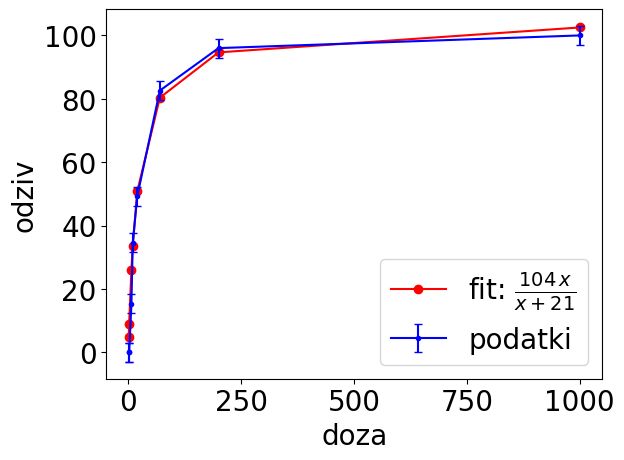

In [1090]:
a = np.linalg.solve(A,b)
std_dev = np.sqrt(var_ai)
confidence_intervals = 1 * std_dev
for i in range(M):
    lower_bound = a[i] - confidence_intervals[i]
    upper_bound = a[i] + confidence_intervals[i]
    #plt.fill_between(x_doza, y(x_doza, 1/upper_bound, upper_bound*1/upper_bound), y(x_doza, 1/lower_bound, lower_bound*1/lower_bound), alpha=0.2)


plt.plot(x_doza, y(x_doza, 1/a[0], a[1]*1/a[0]), 'ro-', label=f'fit: $\\frac{{{int(1/a[0])}\,x}}{{x+{int(a[1]*1/a[0])}}}$')
plt.errorbar(x_doza, y_odziv, dy_odziv, fmt='b.-', capsize=3, label='podatki') #podatki
plt.legend()
plt.xlabel('doza')
plt.ylabel('odziv')
#plt.xscale('log')
#plt.savefig('slike/matricna_en_farm.pdf', bbox_inches='tight')

In [1091]:
napaka_lin = (y_odziv -y(x_doza, 1/a[0], a[1]*1/a[0])) / dy_odziv
napaka_lin, sum(napaka_lin)

(array([-1.57253914, -3.00918275, -3.56499306,  0.34542462, -0.51005592,
         0.74725469,  0.44842835, -0.83697785]),
 -7.952641049581367)

prof zapiski

In [1092]:
#identično!!!
A11 = np.sum(1/sigma_nova**2)
A12 = np.sum(1/x_doza/sigma_nova**2)
A22 = np.sum(1/x_doza**2/sigma_nova**2)
y_data = y_novo
b1 = np.sum(y_data/sigma_nova**2)
b2 = np.sum(y_data/x_doza/sigma_nova**2)

A_ = np.array([[A11, A12], [A12, A22]])
b_ = np.array([b1, b2])
a_ = np.linalg.solve(A_,b_)
a_, a

(array([0.00955264, 0.20241427]), array([0.00955264, 0.20241427]))

In [1093]:
1/a_[0], a_[1] * 1/a_[0], 1/a[0], a[1] * 1/a[0] #ok - isto!

(104.68307340552808,
 21.189347982909627,
 104.68307340552806,
 21.189347982909613)

Levenberg-Marquardt  nelin probolem

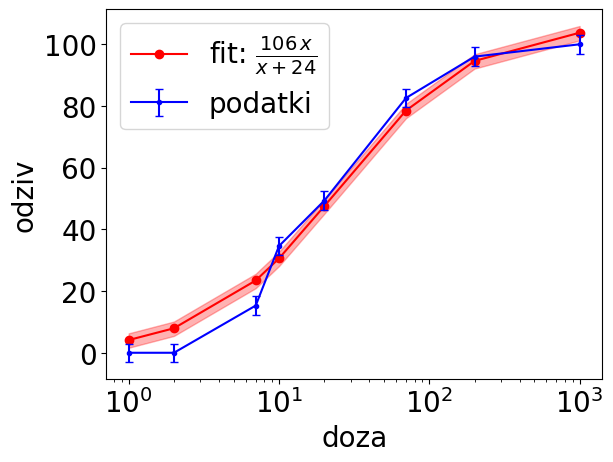

In [1094]:
res = curve_fit(y, x_doza, y_odziv, method='lm',absolute_sigma = True, full_output=True)
a = res[0]
covariance = res[1]
residual_LM_nelin = res[2]['fvec']
nfev = res[2]['nfev'] #number of function calls
std_dev = np.sqrt(np.diag(covariance)) #standard deviation
confidence_intervals = 3 * std_dev

y_data = y(x_doza, a[0], a[1])
plt.fill_between(x_doza, y_data - confidence_intervals[0], y_data + confidence_intervals[1], color='red', alpha=0.3)
plt.plot(x_doza, y_data, 'ro-', label=f'fit: $\\frac{{{int(a[0])}\,x}}{{x+{int(a[1])}}}$')
plt.errorbar(x_doza, y_odziv, dy_odziv, fmt='b.-', capsize=3, label='podatki') #podatki
plt.legend()
plt.xlabel('doza')
plt.ylabel('odziv')
plt.xscale('log')
#plt.savefig('slike/LM_farm.pdf', bbox_inches='tight')

razširjen nelin model

C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\330103835.py:2: RuntimeWarning: invalid value encountered in divide
  return y0*t**p / (t**p + a**p)


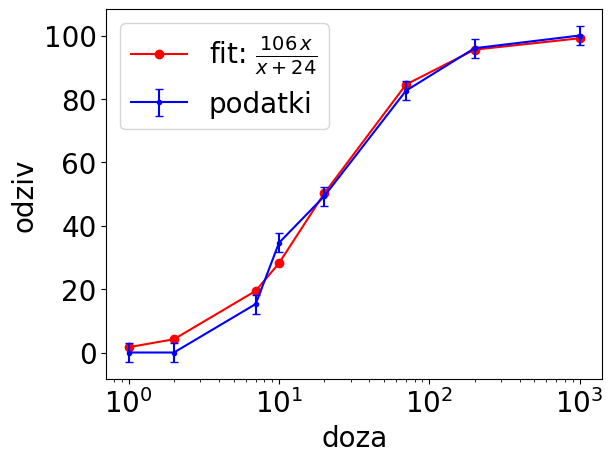

In [1095]:
def nelin(t, y0, a, p):
    return y0*t**p / (t**p + a**p)

res = curve_fit(nelin, x_doza, y_odziv, sigma=dy_odziv ,method='lm', absolute_sigma = True, full_output=True)
param = res[0]
covariance = res[1]
residual_raz = res[2]['fvec']
nfev = res[2]['nfev'] #number of function calls
std_dev = np.sqrt(np.diag(covariance)) #standard deviation
napaka_raz = (-y_odziv + nelin(x_doza, *param))**2 / dy_odziv**2

plt.plot(x_doza, nelin(x_doza, *param), 'ro-', label=f'fit: $\\frac{{{int(a[0])}\,x}}{{x+{int(a[1])}}}$') #popravi label
plt.errorbar(x_doza, y_odziv, dy_odziv, fmt='b.-', capsize=3, label='podatki') #podatki
plt.legend()
plt.xlabel('doza')
plt.ylabel('odziv')
plt.xscale('log')
#plt.savefig('slike/LM_farm.pdf', bbox_inches='tight')

aa = ufloat(a[0], std_dev[0])
bb = ufloat(a[1], std_dev[1])
print("Best fit parameters:\na = {}\nb = {}".format(aa, bb))
flier_kwargs = dict(marker = 'o', markerfacecolor = 'silver',
                    markersize = 3, alpha=0.7)
line_kwargs = dict(color = 'k', linewidth = 1)
bp = plt.boxplot(y(x_doza, a[0], a[1]), positions = x_doza,
                 capprops = line_kwargs,
                 boxprops = line_kwargs,
                 whiskerprops = line_kwargs,
                 medianprops = line_kwargs,
                 flierprops = flier_kwargs,
                 widths = 5,
                 manage_ticks = False)

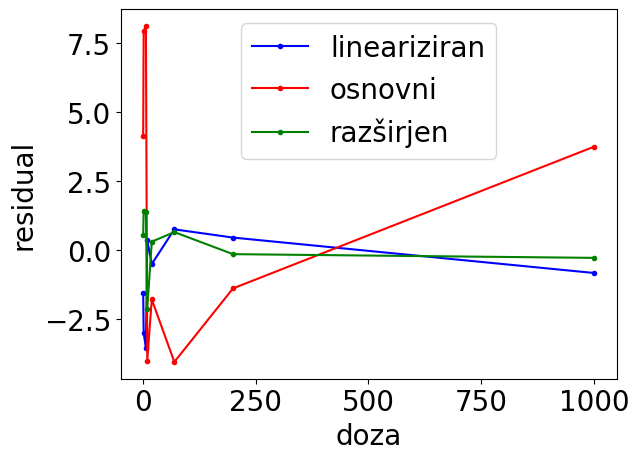

In [1154]:
n = len(x_doza)
plt.plot(x_doza , (napaka_lin), 'b.-', label='lineariziran')
plt.plot(x_doza , (residual_LM_nelin), 'r.-', label='osnovni')
plt.plot(x_doza , (residual_raz), 'g.-', label='razširjen')
#plt.yscale('log')
plt.legend()
plt.xlabel('doza')
plt.ylabel('residual')
#plt.savefig('slike/napaka_modeli.pdf', bbox_inches='tight')

(1.706317130908615, 6.862698635088875, 8)

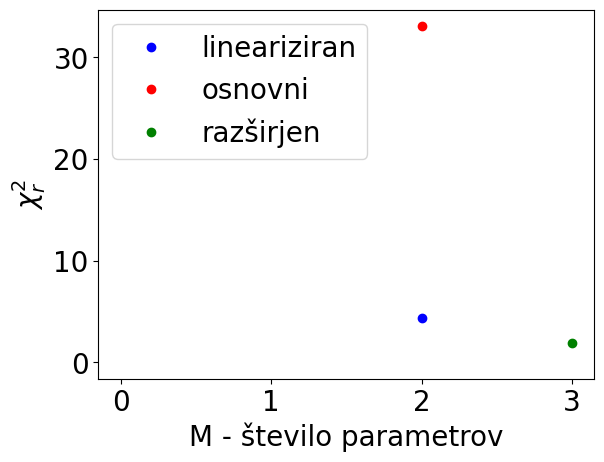

In [1155]:
n=len(y_odziv)
plt.plot(2, sum(napaka_lin**2)/(n-2), 'bo', label='lineariziran')
plt.plot(2, sum((residual_LM_nelin)**2)/(n-2), 'ro', label='osnovni')
plt.plot(3, sum((residual_raz)**2)/(n-3), 'go', label='razširjen')
plt.plot(0,0)
plt.legend()
#plt.yscale('log')
plt.xlabel('M - število parametrov')
plt.ylabel('$\chi_r^2$')
#plt.savefig('slike/chi_farma.pdf', bbox_inches='tight')
sum((residual_raz)), sum(abs(residual_raz)), n

2. naloga ledvice (GPT)

In [1098]:
data = np.loadtxt('ledvice.dat')
t = []
N = []
for vrstica in data:
    t.append(vrstica[0])
    N.append(vrstica[1])
t = np.array(t)
N = np.array(N)

In [1099]:
def enorazdelcni_model(t, λ, c0):
    return c0 * np.exp(-λ * t)
def dvorazdelcni_model(t, A, B, λ1, λ2):
    return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t)
def trorazdelcni(t, A, B, C, λ1, λ2, λ3):
    return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t)
def stirirazdelcni(t, A, B, C, D, λ1, λ2, λ3, λ4):
    return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t) + D * np.exp(-λ4 * t)
def petrazdelcni(t, A, B, C, D, E, λ1, λ2, λ3, λ4, λ5):
    return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t) + D * np.exp(-λ4 * t) + E * np.exp(-λ5 * t)
def enorazdelcni_koren(t, A, λ1):
    return A * np.exp(-λ1 * np.sqrt(t))
def dvorazdelcni_koren(t, A, B, λ1, λ2):
    return A * np.exp(-λ1 * np.sqrt(t)) + B * np.exp(-λ2 * np.sqrt(t))

C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\155500556.py:4: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t)


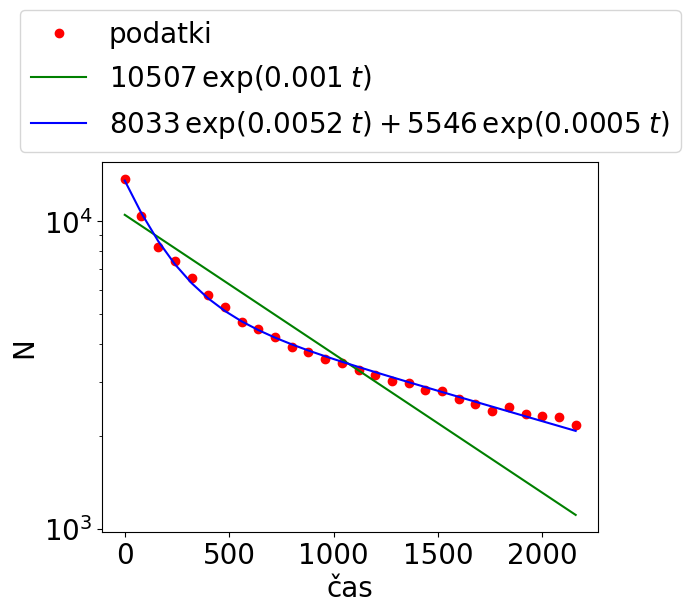

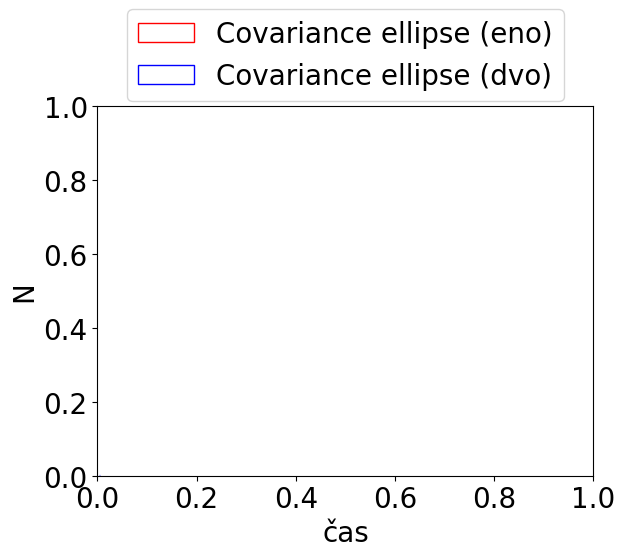

In [1100]:
r1 = curve_fit(enorazdelcni_model, t, N, method='lm',full_output=True, p0=[0.001, N[0]])
param_eno = r1[0]
cov_eno = r1[1]
residual_eno = r1[2]['fvec']
nfev_eno = r1[2]['nfev'] #number of function calls
std_dev = np.sqrt(np.diag(cov_eno)) #standard deviation
čistilnost_eno = enorazdelcni_model(t, *param_eno)
napaka1 = abs(N - np.array(čistilnost_eno))

# Začetni približek: A = 1, B = 10, λ1 = 0.01, λ2 = 0.1
r2 = curve_fit(dvorazdelcni_model, t, N, method='lm', p0=[N[0], 1, 0.01, 0.1],full_output=True)
param_dvo = r2[0]
cov_dvo = r2[1]
residual_dvo = r2[2]['fvec']
nfev_dvo = r2[2]['nfev'] #number of function calls
std_dev_dvo = np.sqrt(np.diag(cov_dvo)) #standard deviation
čistilnost_dvo = dvorazdelcni_model(t, *param_dvo)
napaka2 = abs(N - čistilnost_dvo)

# plt.plot(t, N, 'ro', label='podatki')
# plt.plot(t, čistilnost_eno, 'g-', label=f'${int(param_eno[1])} \, \exp({{{round(param_eno[0],4)} \t t}})$')
# plt.plot(t, čistilnost_dvo, 'b-', label=f'${int(param_dvo[0])} \, \exp({{{round(param_dvo[2],4)} \t t}}) + {int(param_dvo[1])} \, \exp({{{round(param_dvo[3],4)} \t t}})$')
# plt.xlabel('čas')
# plt.ylabel('N')
# plt.legend(bbox_to_anchor=(0.5, 1.45), loc='upper center', ncol=1)
# #plt.savefig('slike/ledvice_LM.pdf', bbox_inches='tight')
# plt.show()

fig, ax = plt.subplots()
ax.plot(t, N, 'ro', label='podatki')
ax.plot(t, čistilnost_eno, 'g-', label=f'${int(param_eno[1])} \, \exp({{{round(param_eno[0],4)} \; t}})$')
ax.plot(t, čistilnost_dvo, 'b-', label=f'${int(param_dvo[0])} \, \exp({{{round(param_dvo[2],4)} \; t}}) + {int(param_dvo[1])} \, \exp({{{round(param_dvo[3],4)} \; t}})$')
ax.set_xlabel('čas')
ax.set_ylabel('N')
ax.legend(bbox_to_anchor=(0.5, 1.45), loc='upper center', ncol=1)
ax.set_yscale('log')
#plt.savefig('slike/ledvice_LM.pdf', bbox_inches='tight')
plt.show()
fig, ax = plt.subplots()
ellipse_eno = Ellipse(xy=(param_eno[0], param_eno[1]), width=std_dev[0]*2, height=std_dev[1]*2, edgecolor='r', facecolor='none', label='Covariance ellipse (eno)')
ax.add_patch(ellipse_eno)
ellipse_dvo = Ellipse(xy=(param_dvo[2], param_dvo[3]), width=std_dev_dvo[2]*2, height=std_dev_dvo[3]*2, edgecolor='b', facecolor='none', label='Covariance ellipse (dvo)')
ax.add_patch(ellipse_dvo)
ax.set_xlabel('čas')
ax.set_ylabel('N')
ax.legend(bbox_to_anchor=(0.5, 1.3), loc='upper center', ncol=1)
plt.show()

# print("Enorazdelčni model:")
# print("Parameter λ:", param_eno[0])
# print("parameter c0: ", param_eno[1])
# print("Dvorazdelčni model:")
# print("Parameter A:", param_dvo[0])
# print("Parameter B:", param_dvo[1])
# print("Parameter λ1:", param_dvo[2])
# print("Parameter λ2:", param_dvo[3])

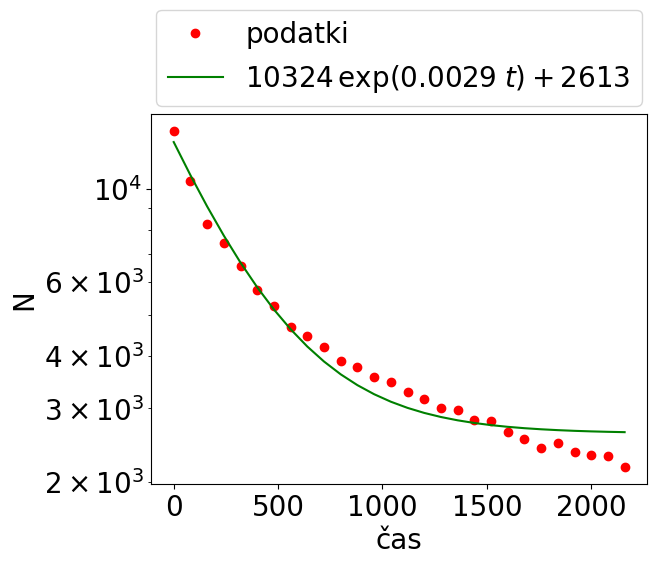

In [1137]:
def ozadje(t, λ, c0, B):
    return c0 * np.exp(-λ * t) + B
r = curve_fit(ozadje, t, N, method='lm', p0=[0.005, N[0], N[-1]], full_output=True)
param_oz = r[0]
cov_oz = r[1]
residual_oz = r[2]['fvec']
nfev_oz = r[2]['nfev'] #number of function calls
std_dev_oz = np.sqrt(np.diag(cov_oz)) #standard deviation
čistilnost_oz = ozadje(t, *param_oz)
napaka_oz = abs(N - čistilnost_oz)

plt.plot(t, N, 'ro', label='podatki')
plt.plot(t, čistilnost_oz, 'g-', label=f'${int(param_oz[1])} \, \exp({{{round(param_oz[0],4)} \; t}}) + {{{int(param_oz[2])}}}$')
plt.xlabel('čas')
plt.ylabel('N')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, 1.32), loc='upper center', ncol=1)
#plt.savefig('slike/ledvice_sevanje_ozadje.pdf', bbox_inches='tight')
plt.show()

C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\2042289278.py:2: RuntimeWarning: overflow encountered in power
  return a * osnova**(-i*t) + b


(array([2.62704965e+00, 1.03244431e+04, 3.01813204e-03, 2.61312786e+03]),
 7555.676322516907)

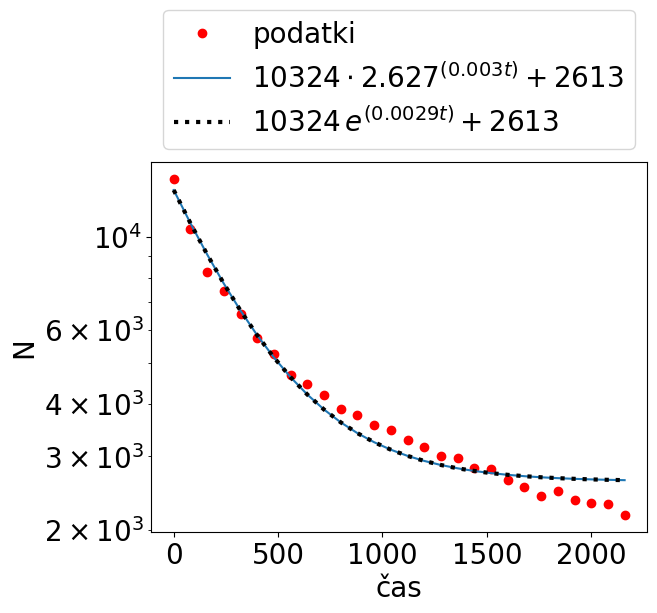

In [1102]:
def poljubna_osnova(t, osnova, a, i, b):
    return a * osnova**(-i*t) + b
plt.plot(t, N, 'ro', label='podatki')
r = curve_fit(poljubna_osnova, t, N, method='lm', p0=[2.7, N[0], 0.01, 1], full_output=True)
param = r[0]
cov_os = r[1]
residual_os = r[2]['fvec']
nfev_os = r[2]['nfev'] #number of function calls
čistilnost = poljubna_osnova(t, *param)
plt.plot(t, čistilnost, label=f'${int(param[1])} \cdot {{{round(param[0],3)}}}^{{({{{round(param[2],4)} \t t}})}} + {{{int(param[3])}}}$')
plt.plot(t, čistilnost_oz, 'k:', label=f'${int(param_oz[1])} \, e^{{({{{round(param_oz[0],4)} \t t}})}} + {{{int(param_oz[2])}}}$', linewidth=3)
plt.yscale('log')
plt.xlabel('čas')
plt.ylabel('N')
plt.legend(bbox_to_anchor=(0.5, 1.45), loc='upper center', ncol=1)
#plt.savefig('slike/ledvice_osnova.pdf', bbox_inches='tight')
napaka_os = abs(N-čistilnost)
param, sum(napaka_os)

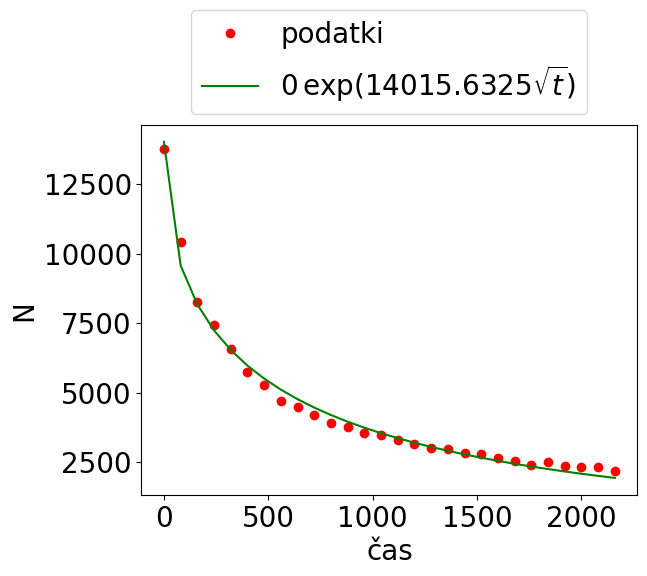

In [1103]:
r = curve_fit(enorazdelcni_koren, t, N, method='lm', p0=[N[0], 0.01], full_output=True)
param_ek = r[0]
cov_ek = r[1]
residual_ek = r[2]['fvec']
nfev_ek = r[2]['nfev'] #number of function calls
std_dev_oek = np.sqrt(np.diag(cov_ek)) #standard deviation
čistilnost_ek = enorazdelcni_koren(t, *param_ek)
napaka_ek = abs(N - čistilnost_ek)

plt.plot(t, N, 'ro', label='podatki')
plt.plot(t, čistilnost_ek, 'g-', label=f'${int(param_ek[1])} \, \exp({{{round(param_ek[0],4)} \t \sqrt{{t}}}})$')
plt.xlabel('čas')
plt.ylabel('N')
#plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, 1.35), loc='upper center', ncol=1)
#plt.savefig('slike/ledvice_sevanje_ozadje.pdf', bbox_inches='tight')
plt.show()

c:\Users\ravni\anaconda3\lib\site-packages\scipy\optimize\_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


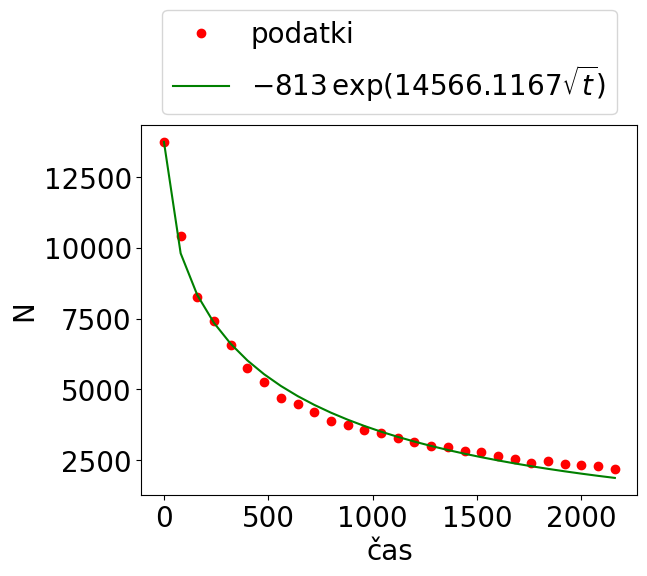

In [1104]:
r = curve_fit(dvorazdelcni_koren, t, N, method='lm', p0=[1000,  1, 0.1, 0.001], full_output=True)
param_ek = r[0]
cov_ek = r[1]
residual_dk = r[2]['fvec']
nfev_dk = r[2]['nfev'] #number of function calls
std_dev_oek = np.sqrt(np.diag(cov_ek)) #standard deviation
čistilnost_ek = dvorazdelcni_koren(t, *param_ek)
napaka_ek = abs(N - čistilnost_ek)

plt.plot(t, N, 'ro', label='podatki')
plt.plot(t, čistilnost_ek, 'g-', label=f'${int(param_ek[1])} \, \exp({{{round(param_ek[0],4)} \t \sqrt{{t}}}})$')
plt.xlabel('čas')
plt.ylabel('N')
#plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, 1.35), loc='upper center', ncol=1)
#plt.savefig('slike/ledvice_sevanje_ozadje.pdf', bbox_inches='tight')
plt.show()

C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\155500556.py:6: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t)
c:\Users\ravni\anaconda3\lib\site-packages\scipy\optimize\_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',
C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\155500556.py:8: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t) + D * np.exp(-λ4 * t)
C:\Users\ravni\AppData\Local\Temp\ipykernel_4376\155500556.py:10: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-λ1 * t) + B * np.exp(-λ2 * t) + C * np.exp(-λ3 * t) + D * np.exp(-λ4 * t) + E * np.exp(-λ5 * t)


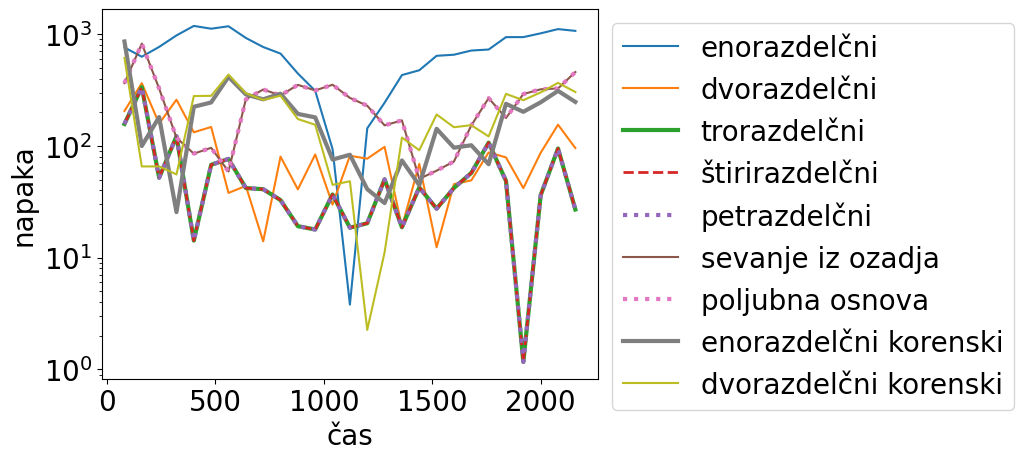

In [1156]:
r1 = curve_fit(trorazdelcni, t, N, method='lm',full_output=True, p0=[N[0], 1, 1, 0.01, 0.1, 1])
param3 = r1[0]
cov3 = r1[1]
residual3 = r1[2]['fvec']
nfev3 = r1[2]['nfev'] #number of function calls
std_dev = np.sqrt(np.diag(cov3)) #standard deviation
čistilnost3 = trorazdelcni(t, *param3)
napaka3 = abs(N - čistilnost3)

r2 = curve_fit(stirirazdelcni, t, N, method='lm', p0=[1, 1, 1, 1, 0.01, 0.1, 1, 1],full_output=True)
param4 = r2[0]
cov4 = r2[1]
residual4 = r2[2]['fvec']
nfev4 = r2[2]['nfev'] #number of function calls
std_dev4 = np.sqrt(np.diag(cov4)) #standard deviation
čistilnost4 = stirirazdelcni(t, *param4)
napaka4 = abs(N - čistilnost4)

r5 = curve_fit(petrazdelcni, t, N, method='lm', p0=[1, 1, 1, 1, 1, 0.01, 0.1, 1, 1, 1],full_output=True)
param5 = r5[0]
cov5 = r5[1]
residual5 = r5[2]['fvec']
nfev5 = r5[2]['nfev'] #number of function calls
std_dev5 = np.sqrt(np.diag(cov5)) #standard deviation
čistilnost5 = petrazdelcni(t, *param5)
napaka5 = abs(N - čistilnost5)

#plt.plot(t, N, 'ro', label='podatki')
#plt.plot(t, čistilnost3, 'g-', label=f'tri ${int(param3[1])} \, \exp({{{round(param3[0],4)} \t t}})$')
#plt.plot(t, čistilnost4, 'g-', label=f'stiri ${int(param4[1])} \, \exp({{{round(param3[0],4)} \t t}})$')
#plt.plot(t, čistilnost5, 'b-', label=f'pet ${int(param5[0])} \, \exp({{{round(param5[2],4)} \t t}}) + {int(param5[1])} \, \exp({{{round(param5[3],4)} \t t}})$')
fig, ax = plt.subplots()
ax.plot(t[1::], abs(residual_eno[1::]), label='enorazdelčni')
ax.plot(t[1::], abs(residual_dvo[1::]), label='dvorazdelčni')
ax.plot(t[1::], abs(residual3[1::]), label='trorazdelčni',linewidth=3.0)
ax.plot(t[1::], abs(residual4[1::]), '--', label='štirirazdelčni',linewidth=2.0)
ax.plot(t[1::], abs(residual5[1::]), ':', label='petrazdelčni', linewidth=3.0)
ax.plot(t[1::], abs(residual_oz[1::]), label='sevanje iz ozadja')
ax.plot(t[1::], abs(residual_os[1::]), ':', label='poljubna osnova', linewidth=3)
ax.plot(t[1::], abs(residual_ek[1::]), '-', label='enorazdelčni korenski', linewidth=3)
ax.plot(t[1::], abs(residual_dk[1::]), '-', label='dvorazdelčni korenski')

ax.set_yscale('log',base=10) 
plt.xlabel('čas')
plt.ylabel('napaka')
plt.legend(bbox_to_anchor=(1,1), ncol=1)
#plt.savefig('slike/ledvice_LM_napake.pdf', bbox_inches='tight')
plt.show()

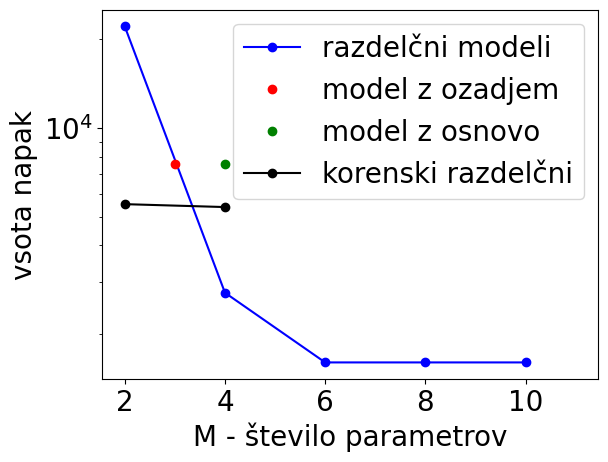

In [1157]:
napake_razdelki = np.array([sum(abs(i)) for i in [residual_eno, residual_dvo, residual3, residual4, residual5]])
st_M = [i*2 for i in range(1,len(napake_razdelki)+1)]
n=len(t)
nn = np.array([n-i for i in st_M])
plt.plot(st_M, napake_razdelki, 'bo-', label='razdelčni modeli')
plt.plot(3, sum(abs(residual_oz)), 'ro', label='model z ozadjem')
plt.plot(4, sum(abs(residual_os)), 'go', label='model z osnovo')
plt.plot([2,4], [sum(abs(residual_ek)), sum(abs(residual_dk))], 'ko-', label='korenski razdelčni')
plt.legend()
plt.plot(11,10000)
plt.xlabel('M - število parametrov')
plt.ylabel('vsota napak')
plt.yscale('log')
#plt.savefig('slike/ledvica_napaka_param.pdf', bbox_inches='tight')

Text(0, 0.5, 'število klicev')

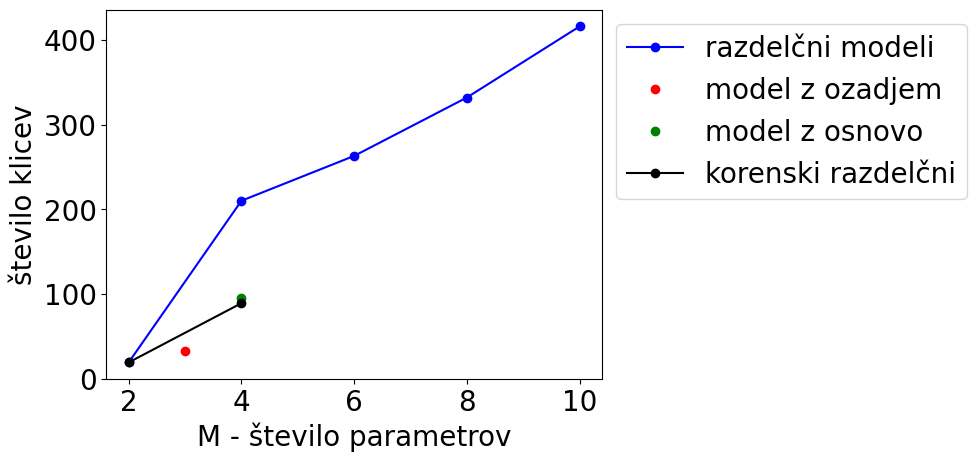

In [1159]:
klici = [i for i in [nfev_eno, nfev_dvo, nfev3, nfev4, nfev5]]
st_M = [i*2 for i in range(1,len(napake_razdelki)+1)]
plt.plot(st_M, klici, 'bo-', label='razdelčni modeli')
plt.plot(3, nfev_oz, 'ro', label='model z ozadjem')
plt.plot(4, nfev, 'go', label='model z osnovo')
plt.plot([2,4], [nfev_ek, nfev_dk], 'ko-', label='korenski razdelčni')
plt.legend(bbox_to_anchor=(1,1), ncol=1)
plt.xlabel('M - število parametrov')
plt.ylabel('število klicev')
#plt.savefig('slike/ledvice_st_klicev.pdf', bbox_inches='tight')

polinomi

In [1108]:
def polinom(t, c0, c1, c2, c3, c4):
    return c0 + c1*t + c2*t**2 + c3*t**3 + c4*t**3
def racional(t, a, b, c):
    return b / (c*t+1) + a
def ln(t, os, a, b): #NI OK
    return a * np.emath.logn(os, t) + b

In [1109]:
res = np.polyfit(t ,N, deg=10)
param = res[0]
residual_poli = res[1]
poly_func = np.poly1d(param)
napaka = N - poly_func(t)
sum(abs(napaka)), residual_poli

(122729.0, -5.140962480268043e-23)

Text(0, 0.5, 'N')

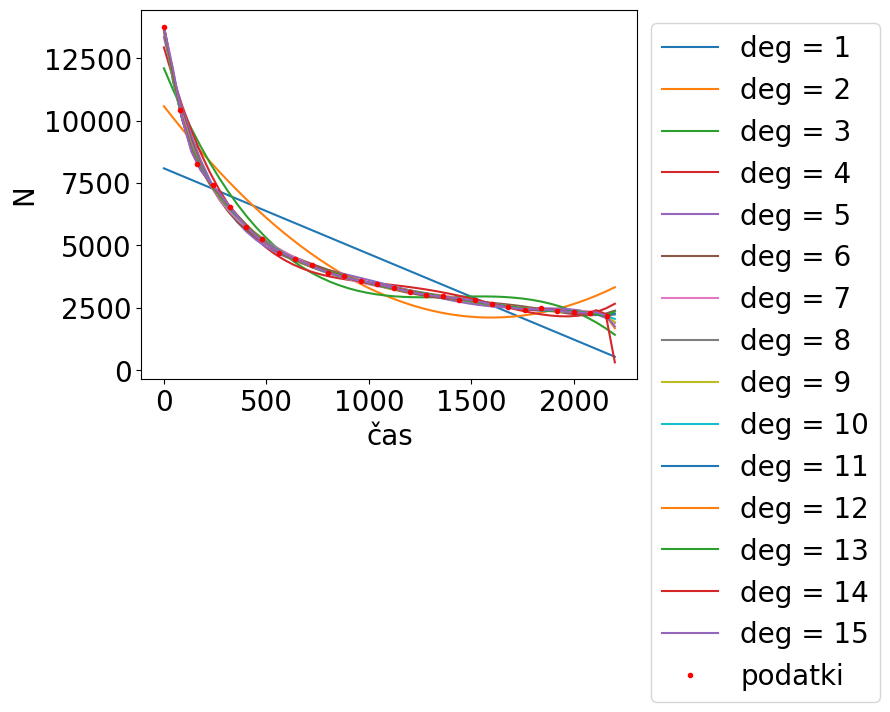

In [1110]:
residual_poli = []
napake = []
stopnje = []
for deg in range(1,1 + 15):
    stopnje.append(deg)
    res = np.polyfit(t, N, deg=deg, full=True)
    param = res[0]
    residual_poli.append(res[1])
    poly_func = np.poly1d(param)
    x =np.linspace(0, 2200)
    čistilnost = poly_func(x)
    plt.plot(x, čistilnost, label=f'deg = {deg}')
    nap = [(N[i]-poly_func(t[i]))**2 for i in range(len(t))]
    napake.append(nap)
plt.plot(t, N, 'r.', label='podatki')
plt.legend(bbox_to_anchor=(1,1), ncol=1)
plt.xlabel('čas')
plt.ylabel('N')
#plt.savefig('slike/ledvice_poli.pdf', bbox_inches='tight')

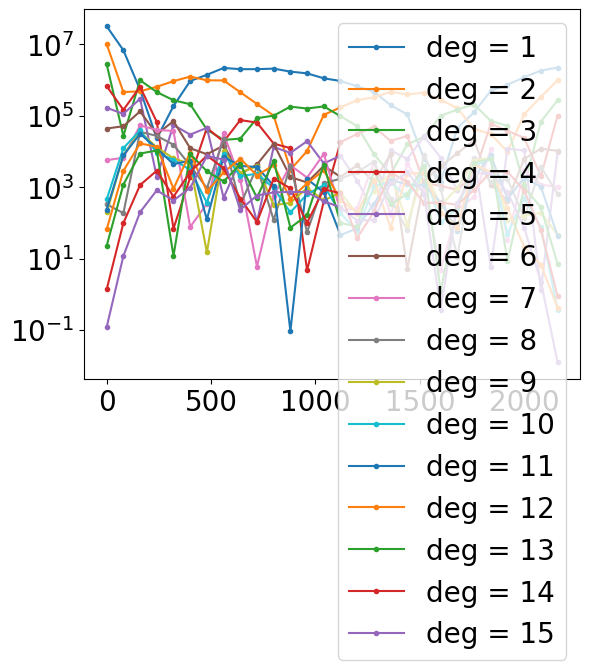

In [1111]:
for i in range(len(napake)):
    plt.plot(t, napake[i], '.-',label=f'deg = {stopnje[i]}')
plt.legend()
plt.yscale('log')

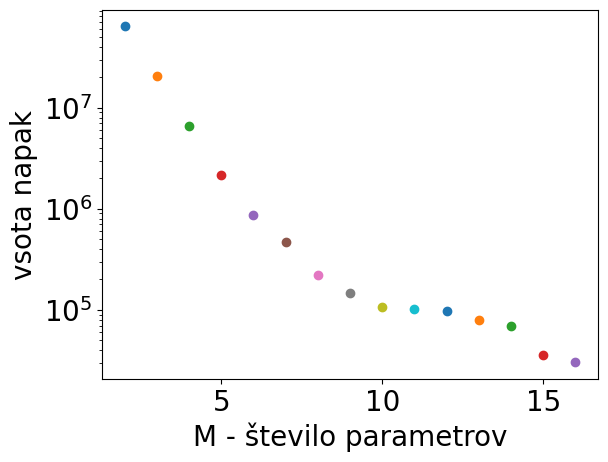

In [1160]:
for i in range(len(stopnje)):
    plt.plot(stopnje[i]+1, residual_poli[i], 'o-', label=f'deg = {stopnje[i]}')
#plt.legend(bbox_to_anchor=(1,1), ncol=1)
plt.xlabel('M - število parametrov')
plt.ylabel('vsota napak')
plt.yscale('log')
#plt.savefig('slike/ledvice_napaka_poli.pdf', bbox_inches='tight')

spektrometer

In [1113]:
data = np.loadtxt('thtg-xfp-thfp.dat')
thtg = []
xfp = []
thfp = []
for vrstica in data:
    thtg.append(vrstica[0])
    xfp.append(vrstica[1])
    thfp.append(vrstica[2])
thtg = np.array(thtg)
xfp = np.array(xfp)
thfp = np.array(thfp)

In [1114]:
def theta_tg_os(x_fp, theta_fp, a):
    a0,a1,a3,a4 = a
    return (a0+a1*x_fp) + (a3+a4*x_fp)*theta_fp
def theta_tg_1(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp+a5*x_fp**2)*theta_fp
def theta_tg_2(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7,a8 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp+a5*x_fp**2)*theta_fp + (a6+a7*x_fp+a8*x_fp**2)*theta_fp**2
def theta_tg_3(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7,a8,a9,a10,a11 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp+a5*x_fp**2)*theta_fp + (a6+a7*x_fp+a8*x_fp**2)*theta_fp**2 + (a9+a10*x_fp+a11*x_fp**2)*theta_fp**3

In [1115]:
def theta_tg_12(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7 = a
    return (a0+a1*x_fp+a2*x_fp**2+a6*x_fp**3) + (a3+a4*x_fp+a5*x_fp+a7*x_fp**3)*theta_fp
def theta_tg_13(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7,a8,a9 = a
    return (a0+a1*x_fp+a2*x_fp**2+a6*x_fp**3+a8*x_fp**4) + (a3+a4*x_fp+a5*x_fp+a7*x_fp**3+a9*x_fp**4)*theta_fp

In [1116]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp))
a, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)
theta_tg_approx = theta_tg_1(xfp, thfp, a)
#print("Optimized coefficients:", a)
napaka = theta_tg_approx - thtg

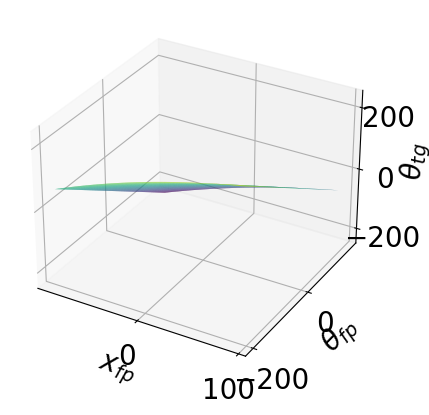

In [1117]:
x = np.linspace(min(xfp), max(xfp), 100)
theta = np.linspace(min(thfp), max(thfp), 100)
x_fp_grid, theta_fp_grid = np.meshgrid(x, theta)
approximated_values_3d = theta_tg_1(x_fp_grid.flatten(), theta_fp_grid.flatten(), a)
approximated_values_3d = approximated_values_3d.reshape(x_fp_grid.shape)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x_fp_grid, theta_fp_grid, approximated_values_3d, cmap='viridis')
ax.set_xlabel('$x_{fp}$')
ax.set_ylabel('$\\theta_{fp}$')
ax.set_zlabel('$\\theta_{tg}$')
plt.show()

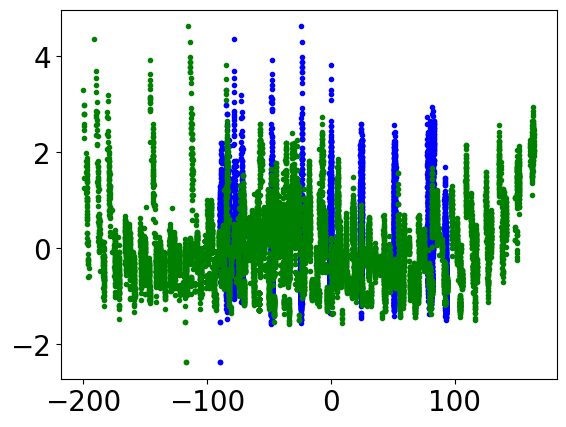

In [1118]:
plt.plot(xfp, napaka, 'b.')
plt.plot(thfp, napaka, 'g.')

In [1119]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, thfp, xfp * thfp))
a_os, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [1120]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp))
a1, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [1121]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp, 
                                 thfp ** 2, xfp * thfp ** 2, xfp ** 2 * thfp ** 2, 
                                 ))
a2, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [1122]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp, 
                                 thfp ** 2, xfp * thfp ** 2, xfp ** 2 * thfp ** 2, 
                                 thfp ** 3, xfp * thfp ** 3, xfp ** 2 * thfp ** 3
                                 ))
a3, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

Text(0, 0.5, '$\\theta_{tg}$')

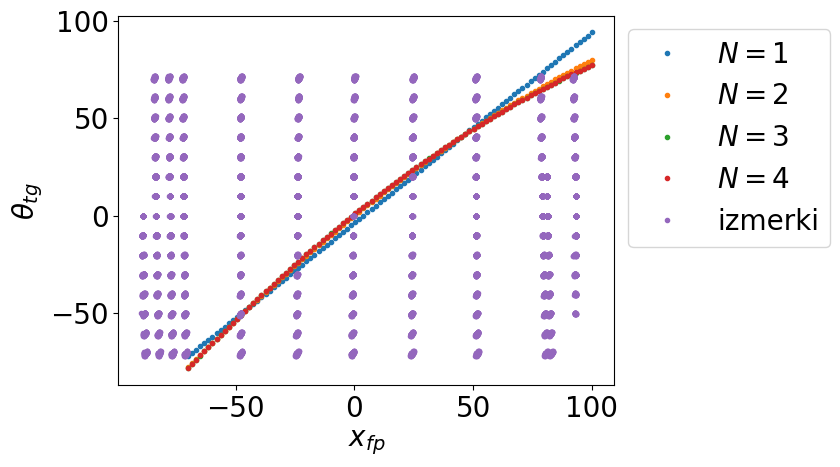

In [1123]:
# M = 2 konst.
x = np.linspace(-70, 100, 100)
theta = np.array([1 for i in x])
plt.plot(x, theta_tg_os(x, theta, a_os), '.', label=f'$N = 1$')
plt.plot(x, theta_tg_1(x, theta, a1), '.', label=f'$N = 2$')
#plt.plot(theta, theta_tg_1(x, theta, a1), '.', label=f'$\\theta_{{fp}}$, $p=1$')
plt.plot(x, theta_tg_2(x, theta, a2), '.', label=f'$N = 3$')
#plt.plot(theta, theta_tg_2(x, theta, a2), '.', label=f'$\\theta_{{fp}}$, $p=2$')
plt.plot(x, theta_tg_3(x, theta, a3), '.', label=f'$N = 4$')
#plt.plot(theta, theta_tg_3(x, theta, a3), '.', label=f'$\\theta_{{fp}}$, $p=3$')
plt.plot(xfp, thtg, '.', label='izmerki')
plt.xlabel('$x_{fp}$')
plt.legend(bbox_to_anchor=(1,1))
plt.ylabel('$\\theta_{tg}$')
#plt.savefig('slike/spektro_red_theta.pdf', bbox_inches='tight')

In [1124]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, xfp ** 3, thfp, xfp * thfp, xfp ** 2 * thfp, xfp ** 3 * thfp))
a12, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [1125]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, xfp ** 3, xfp ** 4, thfp, xfp * thfp, xfp ** 2 * thfp, xfp ** 3 * thfp, xfp ** 4 *thfp))
a13, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

Text(0, 0.5, '$\\theta_{tg}$')

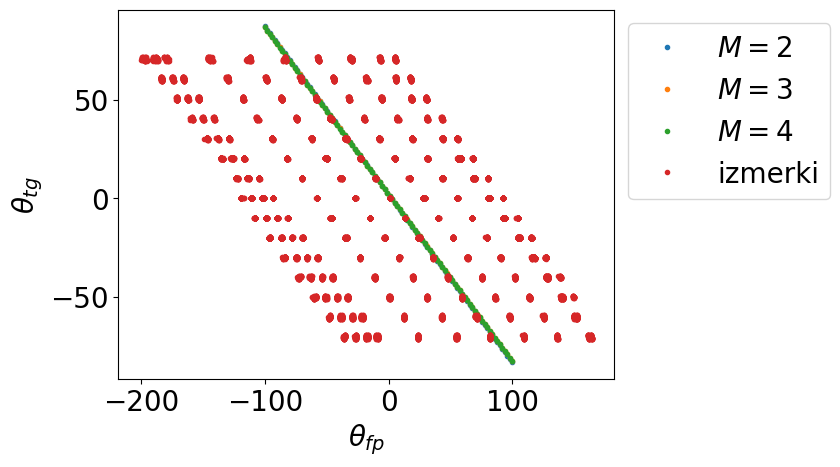

In [1126]:
# N = 1 konst.
theta = np.linspace(-100, 100, 100)
x = np.array([1 for i in theta])
#plt.plot(x, theta_tg_1(x, theta, a1), 'o', label=f'$x_{{fp}}$, $q = 2$')
plt.plot(theta, theta_tg_1(x, theta, a1), '.', label=f'$M=2$')
#plt.plot(x, theta_tg_12(x, theta, a12), 'o', label=f'$x_{{fp}}$, $q = 3$')
plt.plot(theta, theta_tg_12(x, theta, a12), '.', label=f'$M=3$')
#plt.plot(x, theta_tg_13(x, theta, a13), 'o', label=f'$x_{{fp}}$, $q = 4$')
plt.plot(theta, theta_tg_13(x, theta, a13), '.', label=f'$M=4$')
plt.plot(thfp, thtg, '.', label='izmerki')
plt.xlabel('$\\theta_{fp}$')
plt.legend(bbox_to_anchor=(1,1))
plt.ylabel('$\\theta_{tg}$')
#plt.savefig('slike/spektro_red_x.pdf', bbox_inches='tight')

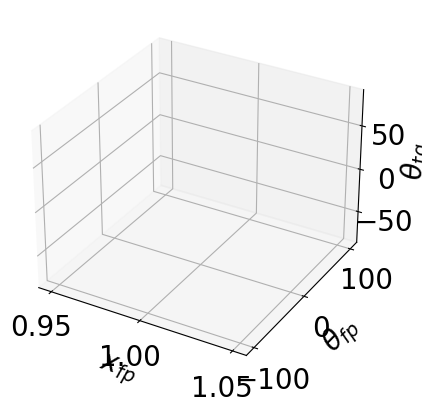

In [1127]:
x, theta = np.meshgrid(x, theta)
rez = theta_tg_1(x, theta, a)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, theta, rez, cmap='Blues')
#ax.scatter(xfp, thfp, theta_tg_1(xfp,thfp,a))
#ax.scatter(xfp, thfp, thtg)
ax.set_xlabel('$x_{fp}$')
ax.set_ylabel('$\\theta_{fp}$')
ax.set_zlabel('$\\theta_{tg}$')
ax.grid(True)
plt.show()

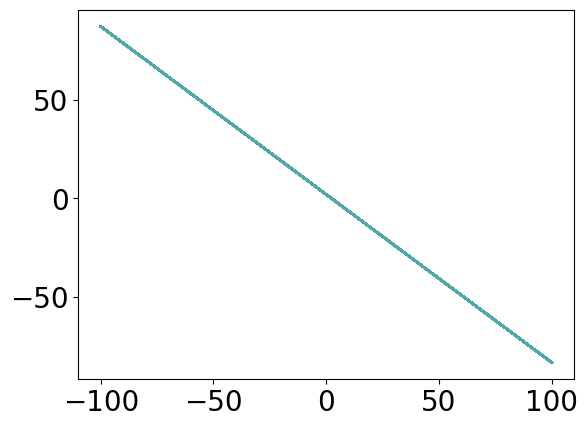

In [1128]:
plt.plot(theta, rez)